# Laboratorio 2

**Nombre:** Laura Ostos

**C.C:** 1010107809


In [2]:
# PARTE 1: Series de tiempo: EUR/USD

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

import re
from scipy import stats

sns.set_style("whitegrid")

# ==========================================================================================

# 1. lectura del dataset
url = "https://raw.githubusercontent.com/hernansalinas/Curso_aprendizaje_estadistico/main/datasets/Pandas_data_historical_dataEURUSD.csv"
df = pd.read_csv(url)

df = df.drop(columns=[df.columns[0]])
df.head()

# ==========================================================================================

# 2. Definir la columna de tiempo como indice
df["time"] = pd.to_datetime(df["time"])
df = df.set_index("time")
df.head()

# ==========================================================================================

# 3. Informacion del dataframe
df.info()

# ==========================================================================================

# 4. Valores nulos
df.isnull().sum().sum()

# ==========================================================================================

# 5. Notacion Pascal Case: se trabaja con la columna del precio de cierre
df = df.rename(columns={"close":"Close"})
df_close = df[["Close"]].copy()
df_close.head()


<class 'pandas.core.frame.DataFrame'>
DatetimeIndex: 5000 entries, 2022-07-25 13:00:00 to 2023-05-12 23:00:00
Data columns (total 11 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   open                5000 non-null   float64
 1   high                5000 non-null   float64
 2   low                 5000 non-null   float64
 3   close               5000 non-null   float64
 4   tick_volume         5000 non-null   int64  
 5   spread              5000 non-null   int64  
 6   real_volume         5000 non-null   int64  
 7   MeanCloseOpen       5000 non-null   float64
 8   Diff_Close          5000 non-null   float64
 9   Diff_Open           5000 non-null   float64
 10  Diff_MeanCloseOpen  5000 non-null   float64
dtypes: float64(8), int64(3)
memory usage: 468.8 KB


,Close
time,
2022-07-25 13:00:00,1.02345
2022-07-25 14:00:00,1.02299
2022-07-25 15:00:00,1.02457
2022-07-25 16:00:00,1.02485
2022-07-25 17:00:00,1.02181


In [6]:
python -m pip install fitter

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 9.9/9.9 MB 22.1 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 12.0/12.0 MB 60.3 MB/s  0:00:00
  Attempting uninstall: pandas
    Found existing installation: pandas 2.2.3
    Uninstalling pandas-2.2.3:
      Successfully uninstalled pandas-2.2.3
  Attempting uninstall: matplotlib
    Found existing installation: matplotlib 3.10.0
    Uninstalling matplotlib-3.10.0:
      Successfully uninstalled matplotlib-3.10.0
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 4/4 [fitter]
ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
google-colab 1.0.0 requires pandas==2.2.3, but you have pandas 3.1.1 which is incompatible.


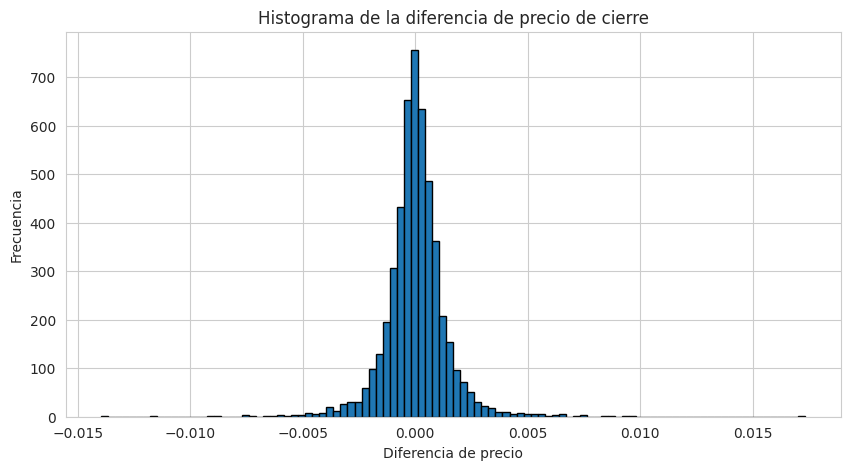

(np.float64(14614.580587503446),
 np.float64(27364.936692417796),
 np.float64(-0.20966354340428084),
 np.float64(0.6022808056526019))

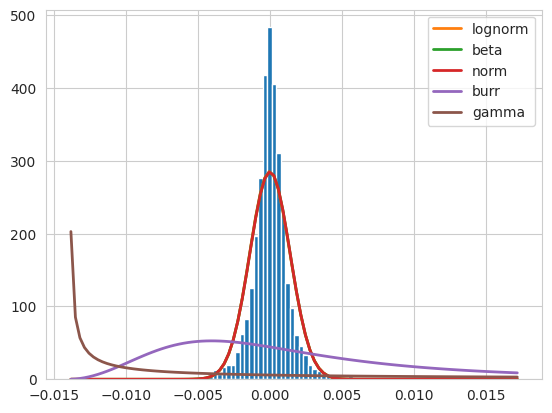

In [7]:
# 6. Distribucion Estadistica de la diferencia de precio
# diferencia de precio
df_close["DiffPrice"] = df_close["Close"].diff()
df_close = df_close.dropna() # elimina la primera fila
df_close.head()

# histograma
plt.figure(figsize=(10, 5))
plt.hist(df_close["DiffPrice"], bins=100, edgecolor="black")
plt.title("Histograma de la diferencia de precio de cierre")
plt.xlabel("Diferencia de precio")
plt.ylabel("Frecuencia")
plt.show()

# mejor distribucion estadistica  con fitter
from fitter import Fitter, get_common_distributions, get_distributions

data = df_close["DiffPrice"].values
f = Fitter(data, distributions=['gamma', 'lognorm', "beta", "burr", "norm"])
f.fit()
f.summary()

# Indentificamos la mejor distribucion con el error cuadratico medio
mejor= f.get_best(method = 'sumsquare_error')
mejor

# Indentificamos parametros de la distrubicion beta
f.fitted_param["beta"]



In [8]:
# 7. filtdado: Solo datos de 2023
df_2023 = df_close[df_close.index.year == 2023].copy()
df_2023.head()

,Close,DiffPrice
time,,
2023-01-02 00:00:00,1.06796,-0.00200
2023-01-02 01:00:00,1.06965,0.00169
2023-01-02 02:00:00,1.07058,0.00093
2023-01-02 03:00:00,1.06896,-0.00162
2023-01-02 04:00:00,1.06880,-0.00016


In [9]:
# 8. promedios con distintas periodicidades
# promedio 15 días
prom_15d = df_2023.groupby(pd.Grouper(freq="15D")).mean()
prom_15d

# promedio 1 semana
prom_1s = df_2023.groupby(pd.Grouper(freq="1W")).mean()
prom_1s

# promedio 1 mes
prom_1m = df_2023.groupby(pd.Grouper(freq="1ME")).mean()
prom_1m


,Close,DiffPrice
time,,
2023-01-31,1.077463,0.000031
2023-02-28,1.071167,-0.000060
2023-03-31,1.070874,0.000049
2023-04-30,1.096051,0.000036
2023-05-31,1.098980,-0.000069


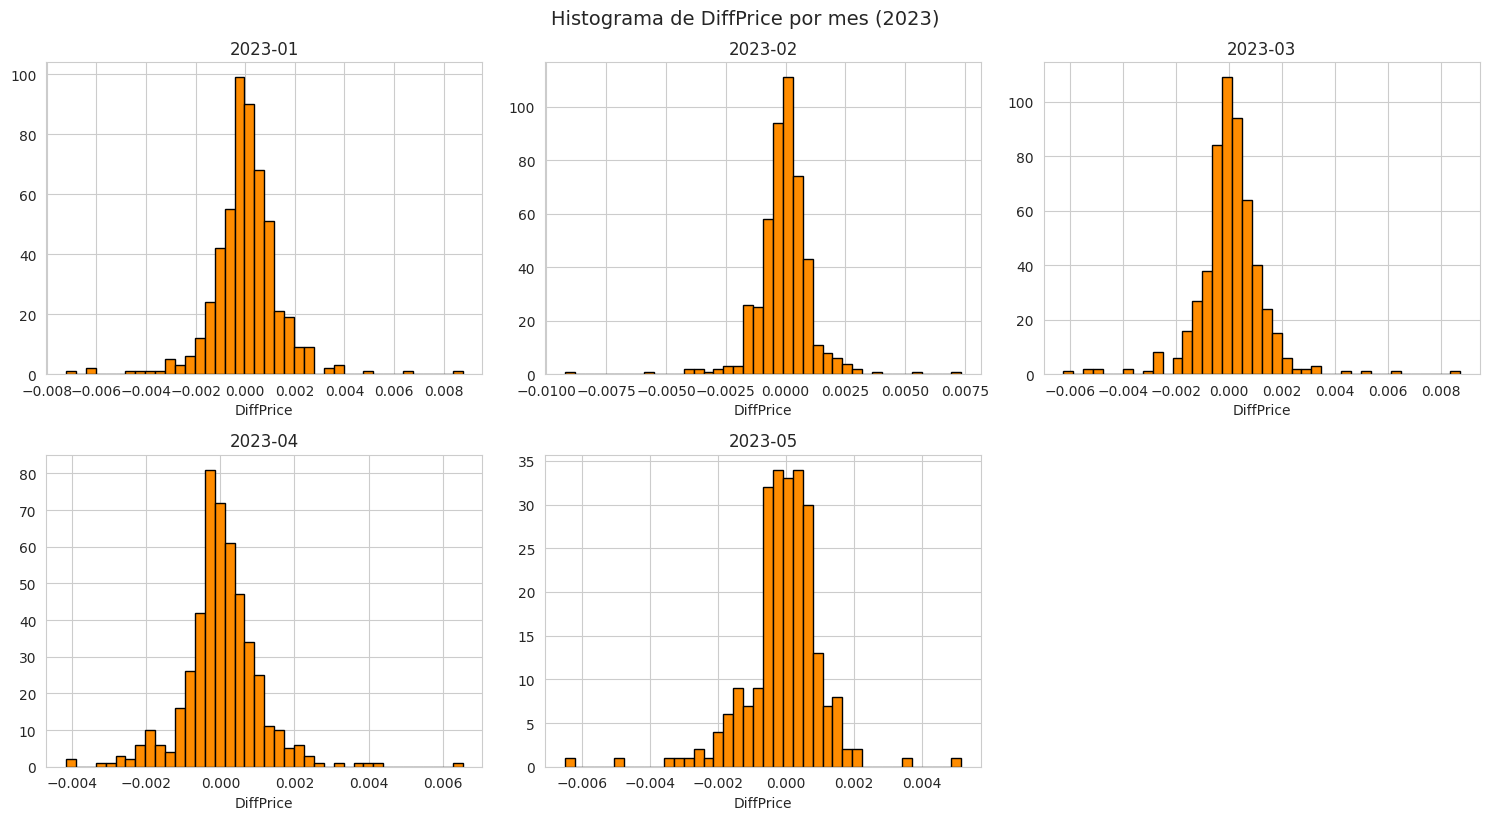

In [10]:
# 9. Histograma de DiffPrice para cada mes de 2023
grupo_mensual = df_2023.groupby(pd.Grouper(freq="1ME"))

n_meses = len(grupo_mensual)
n_cols = 3
n_rows = int(np.ceil(n_meses / n_cols))

fig, axes = plt.subplots(n_rows, n_cols, figsize=(15, 4 * n_rows))
axes = axes.flatten()

for ax, (nombre_mes, grupo) in zip(axes, grupo_mensual):
    ax.hist(grupo["DiffPrice"], bins=40, color="darkorange", edgecolor="black")
    ax.set_title(nombre_mes.strftime("%Y-%m"))
    ax.set_xlabel("DiffPrice")

# Ocultamos ejes sobrantes si el número de meses no llena la grilla
for ax in axes[n_meses:]:
    ax.axis("off")

plt.tight_layout()
plt.suptitle("Histograma de DiffPrice por mes (2023)", y=1.02, fontsize=14)
plt.show()


In [11]:
# PARTE 2: Análisis de datos con pandas a Breast Cancer Wisconsin (Diagnostic)

# Lectura de datos
url_cancer = "https://archive.ics.uci.edu/ml/machine-learning-databases/breast-cancer-wisconsin/wdbc.data"
base_features = ["radius", "texture", "perimeter", "area", "smoothness",
                  "compactness", "concavity", "concave_points", "symmetry",
                  "fractal_dimension"]

column_names = ["id", "diagnosis"]
for suffix in ["mean", "se", "worst"]:
    column_names += [f"{feat}_{suffix}" for feat in base_features]

try:
    cancer = pd.read_csv(url_cancer, header=None, names=column_names)
except Exception:
    print("No fue posible descargar el archivo directamente desde archive.ics.uci.edu "
          "(puede deberse a restricciones de red). Se usa el paquete 'ucimlrepo' como alternativa.")
    # pip install ucimlrepo --quiet
    from ucimlrepo import fetch_ucirepo

    dataset = fetch_ucirepo(id=17)
    X = dataset.data.features.reset_index(drop=True)
    y = dataset.data.targets.reset_index(drop=True)

    cancer = X.copy()
    cancer.columns = column_names[2:]          # mismas 30 columnas, mismo orden
    cancer.insert(0, "diagnosis", y.iloc[:, 0]) # etiqueta B/M
    cancer.insert(0, "id", range(1, len(cancer) + 1))

cancer.head()

# ==========================================================================================

# 2. Renombrar columnas en Pascal Case
def pascal_case(col):
    partes = col.split("_")
    return "".join(p.capitalize() for p in partes)

cancer.columns = [pascal_case(str(c)) for c in cancer.columns]
cancer.head()

# ==========================================================================================

# 3. Metodos head, tail, describe, info
cancer.head()
cancer.tail()
cancer.describe()
cancer.info()

# ==========================================================================================

# 4. Conteo de valores nulos / NaN
cancer.isnull().sum()

# ==========================================================================================

# 5. Valores unicos en la columna target
cancer["Diagnosis"].unique()


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 569 entries, 0 to 568
Data columns (total 32 columns):
 #   Column                 Non-Null Count  Dtype  
---  ------                 --------------  -----  
 0   Id                     569 non-null    int64  
 1   Diagnosis              569 non-null    object 
 2   RadiusMean             569 non-null    float64
 3   TextureMean            569 non-null    float64
 4   PerimeterMean          569 non-null    float64
 5   AreaMean               569 non-null    float64
 6   SmoothnessMean         569 non-null    float64
 7   CompactnessMean        569 non-null    float64
 8   ConcavityMean          569 non-null    float64
 9   ConcavePointsMean      569 non-null    float64
 10  SymmetryMean           569 non-null    float64
 11  FractalDimensionMean   569 non-null    float64
 12  RadiusSe               569 non-null    float64
 13  TextureSe              569 non-null    float64
 14  PerimeterSe            569 non-null    float64
 15  AreaSe

array(['M', 'B'], dtype=object)

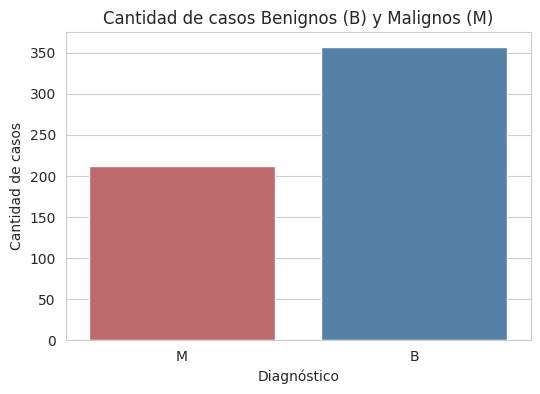

In [12]:
# 6. Conteo de casos B y M
plt.figure(figsize=(6, 4))
sns.countplot(data=cancer, x="Diagnosis", hue="Diagnosis",
              palette={"B": "steelblue", "M": "indianred"}, legend=False)
plt.title("Cantidad de casos Benignos (B) y Malignos (M)")
plt.xlabel("Diagnóstico")
plt.ylabel("Cantidad de casos")
plt.show()


In [13]:
# 7.  Columna DiagnosisNumeric: se asigna 0 y 1.
cancer["DiagnosisNumeric"] = cancer["Diagnosis"].map({"B": 0, "M": 1})
cancer[["Diagnosis", "DiagnosisNumeric"]].head()

,Diagnosis,DiagnosisNumeric
0,M,1
1,M,1
2,M,1
3,M,1
4,M,1


In [14]:
# 8. Normalizacion
cols_numericas = cancer.columns.difference(["Id", "Diagnosis", "DiagnosisNumeric"])

cancer_normalizado = cancer.copy()
cancer_normalizado[cols_numericas] = (
    cancer[cols_numericas] - cancer[cols_numericas].mean()
) / cancer[cols_numericas].std()

cancer_normalizado[cols_numericas].head()


,AreaMean,AreaSe,AreaWorst,CompactnessMean,CompactnessSe,CompactnessWorst,ConcavePointsMean,ConcavePointsSe,ConcavePointsWorst,ConcavityMean,...,RadiusWorst,SmoothnessMean,SmoothnessSe,SmoothnessWorst,SymmetryMean,SymmetrySe,SymmetryWorst,TextureMean,TextureSe,TextureWorst
0,0.983510,2.485391,1.999478,3.280628,1.315704,2.614365,2.530249,0.660239,2.294058,2.650542,...,1.885031,1.567087,-0.213814,1.306537,2.215566,1.147747,2.748204,-2.071512,-0.564768,-1.358098
1,1.907030,0.741749,1.888827,-0.486643,-0.692317,-0.430066,0.547662,0.259933,1.086129,-0.023825,...,1.804340,-0.826235,-0.604819,-0.375282,0.001391,-0.804742,-0.243675,-0.353322,-0.875473,-0.368879
2,1.557513,1.180298,1.455004,1.052000,0.814257,1.081980,2.035440,1.423575,1.953282,1.362280,...,1.510541,0.941382,-0.296744,0.526944,0.938859,0.236827,1.151242,0.455786,-0.779398,-0.023953
3,-0.763792,-0.288125,-0.549538,3.399917,2.741868,3.889975,1.450431,1.114027,2.173873,1.914213,...,-0.281217,3.280667,0.689095,3.391291,2.864862,4.728520,6.040726,0.253509,-0.110312,0.133866
4,1.824624,1.189310,1.219651,0.538866,-0.048477,-0.313119,1.427237,1.143199,0.728618,1.369806,...,1.297434,0.280125,1.481763,0.220362,-0.009552,-0.360775,-0.867590,-1.150804,-0.789549,-1.465481


In [15]:
# 9. Agrupacion por caracteristicas
patron = re.compile(r'^[A-Za-z]+?(?=(Mean|Se|Worst)$)')

grupos = {}
for col in grupos:
    match = patron.match(col)
    if match:
        base = match.group(0)
        grupos.setdefault(base, []).append(col)

list(grupos.items())[:3]

cancer_promedios = cancer[["Id", "Diagnosis"]].copy()

for base, columnas in grupos.items():
    cancer_promedios[f"{base}Avg"] = cancer[columnas].mean(axis=1)

cancer_promedios.head()


,Id,Diagnosis
0,842302,M
1,842517,M
2,84300903,M
3,84348301,M
4,84358402,M


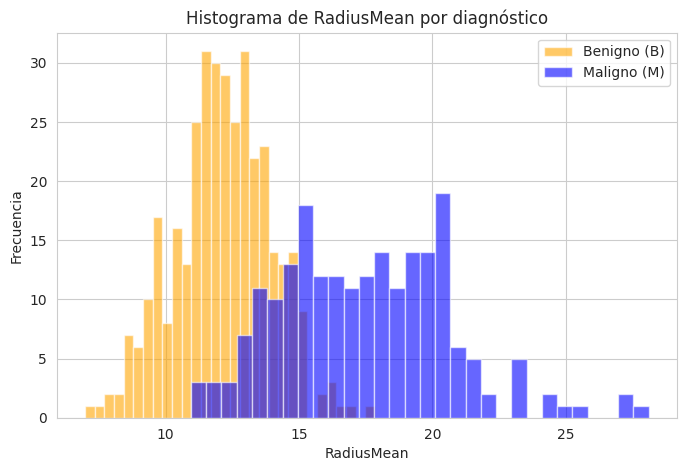

In [16]:
# 10. Histogram de RadiusMean
plt.figure(figsize=(8, 5))
plt.hist(cancer.loc[cancer["Diagnosis"] == "B", "RadiusMean"],
         bins=30, alpha=0.6, color="orange", label="Benigno (B)")
plt.hist(cancer.loc[cancer["Diagnosis"] == "M", "RadiusMean"],
         bins=30, alpha=0.6, color="blue", label="Maligno (M)")
plt.title("Histograma de RadiusMean por diagnóstico")
plt.xlabel("RadiusMean")
plt.ylabel("Frecuencia")
plt.legend()
plt.show()


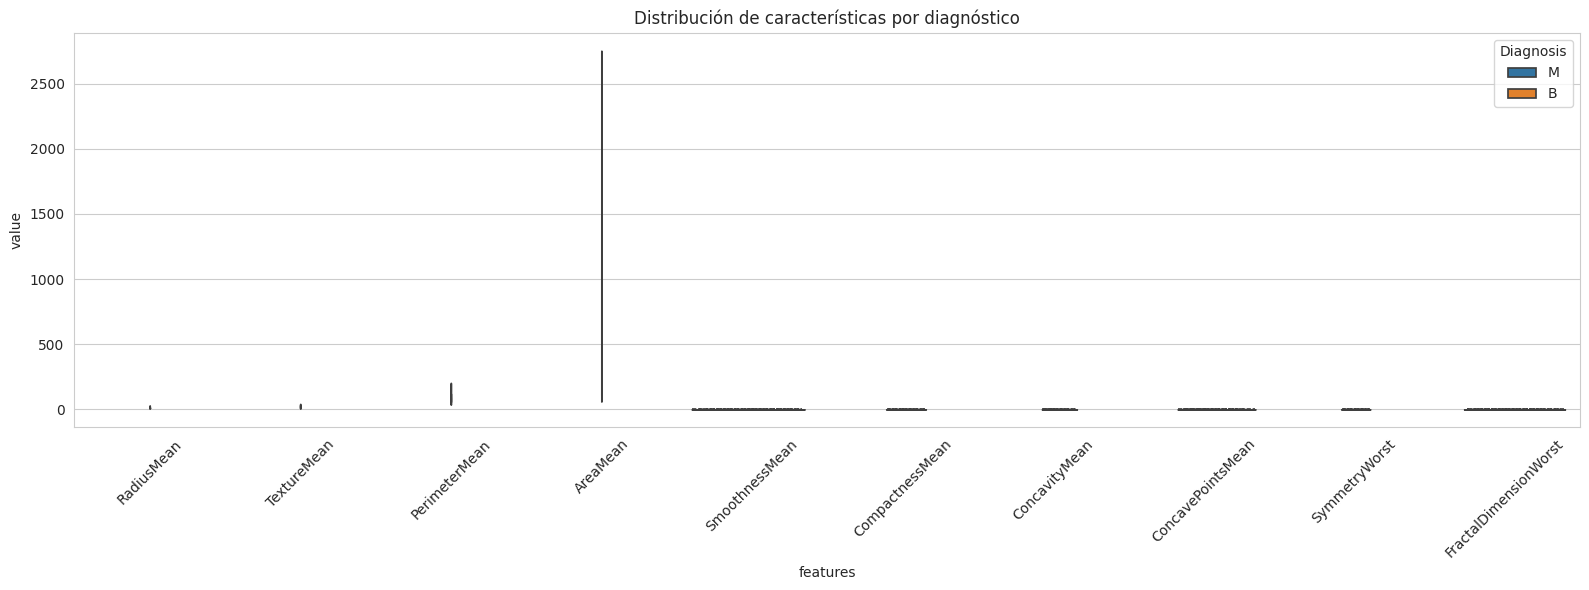

In [17]:
# 11. Graficos de violin para multiple caracteristicas.
columnas_violin = ["RadiusMean", "TextureMean", "PerimeterMean", "AreaMean",
                    "SmoothnessMean", "CompactnessMean", "ConcavityMean",
                    "ConcavePointsMean", "SymmetryWorst", "FractalDimensionWorst"]

datos_violin = cancer[["Diagnosis"] + columnas_violin]

data_melt = pd.melt(datos_violin, id_vars="Diagnosis",
                     var_name="features", value_name="value")

plt.figure(figsize=(16, 6))
sns.violinplot(x="features", y="value", hue="Diagnosis",
               data=data_melt, split=True, inner="quart")
plt.xticks(rotation=45)
plt.title("Distribución de características por diagnóstico")
plt.tight_layout()
plt.show()


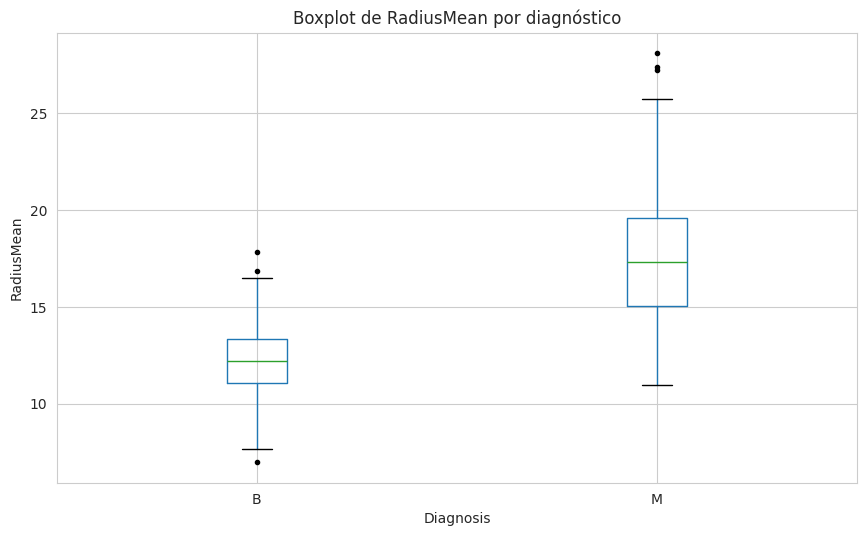

Límite inferior: 5.580 | Límite superior: 21.900
Filas antes: 569 | Filas después: 555 | Eliminadas: 14


In [18]:
# 12. Determinar y eliminar los valores atípicos
cancer.boxplot(column="RadiusMean", by="Diagnosis", sym="k.", figsize=(10, 6))
plt.title("Boxplot de RadiusMean por diagnóstico")
plt.suptitle("")
plt.ylabel("RadiusMean")
plt.show()

Q1 = cancer["RadiusMean"].quantile(0.25)
Q3 = cancer["RadiusMean"].quantile(0.75)
IQR = Q3 - Q1

lim_inf = Q1 - 1.5 * IQR
lim_sup = Q3 + 1.5 * IQR

n_antes = len(cancer)

cancer_sin_atipicos = cancer[~((cancer["RadiusMean"] < lim_inf) | (cancer["RadiusMean"] > lim_sup))].copy()

n_despues = len(cancer_sin_atipicos)

print(f"Límite inferior: {lim_inf:.3f} | Límite superior: {lim_sup:.3f}")
print(f"Filas antes: {n_antes} | Filas después: {n_despues} | Eliminadas: {n_antes - n_despues}")


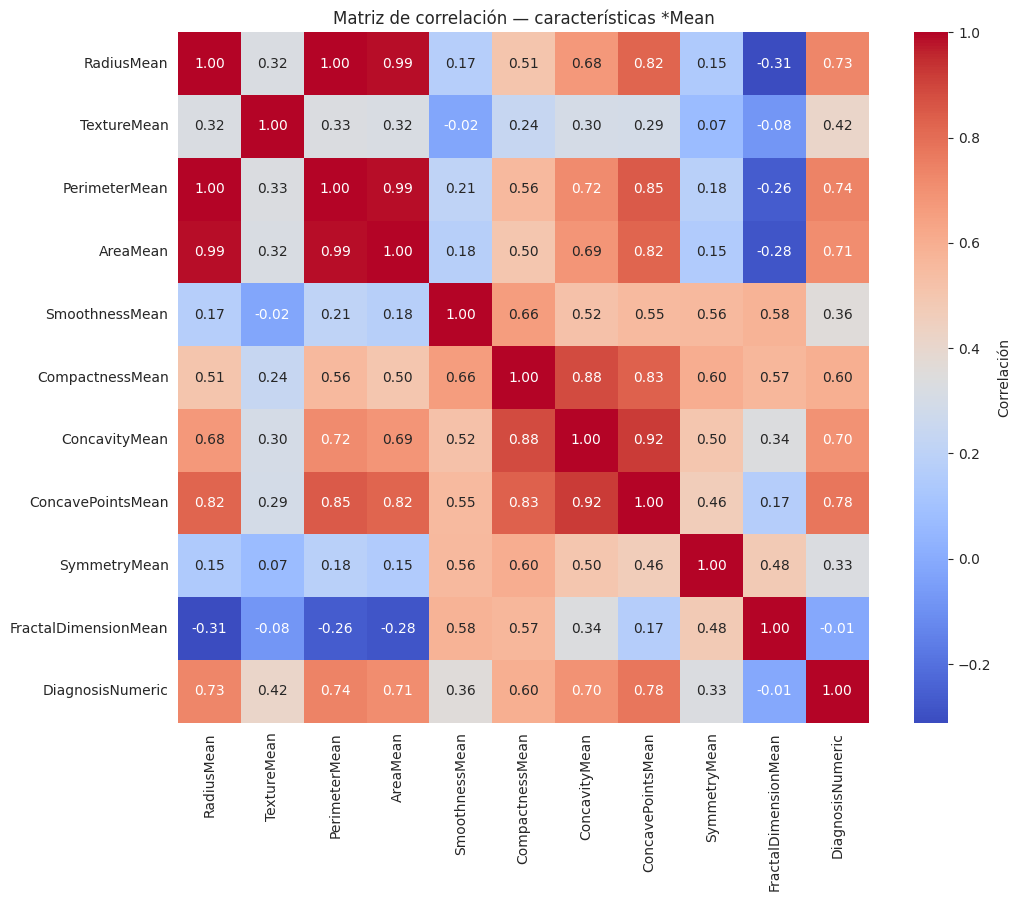

In [19]:
# 13. Matriz de correlacion y heatmap
columnas_mean = [c for c in cancer.columns if c.endswith("Mean")]
corr = cancer[columnas_mean + ["DiagnosisNumeric"]].corr()

plt.figure(figsize=(11, 9))
sns.heatmap(corr, annot=True, fmt=".2f", cmap="coolwarm", square=True,
            cbar_kws={"label": "Correlación"})
plt.title("Matriz de correlación — características *Mean")
plt.tight_layout()
plt.show()


In [20]:
# 14. Otras graficas
print("Pairplot: matriz de dispersion entre varias variables a la vez.")
print("PCA: con un gráfico 2D de los dos primeros componentes.")
print("Boxplots comparativos: de todas las variables mean normalizados")


Pairplot: matriz de dispersion entre varias variables a la vez.
PCA: con un gráfico 2D de los dos primeros componentes.
Boxplots comparativos: de todas las variables mean normalizados
